# A hybrid quantum–classical agent that plays Doom

**SC4055 Introduction to Quantum Computing: project summary**

This notebook summarises what we built, why we built it that way, and what it achieved. Every number and figure is loaded from the files in `results/` and `docs/`, so the notebook can be re-run to check them.

**In one paragraph.** We train a small neural network with a **6-qubit variational quantum circuit** at its core to play full levels of Freedoom (the free Doom-compatible game) from screen pixels plus a few game features. The network learns by **behaviour cloning**: it imitates a rule-based "teacher" that has privileged access to the level map. Most of the engineering effort went into making that teacher competent, because a student cannot beat its teacher. Every trained model is evaluated twice: once with our own PyTorch state-vector simulator, and again with the circuit executed by **PennyLane**. This confirms the trained quantum weights mean the same thing in a standard quantum-computing framework.

| Level | Model | Completion rate | PennyLane re-run |
|---|---|---|---|
| E1M1 | `e1m1_v4` | **98%** (49/50) | identical, 50/50 episodes |
| E1M2 | `e1m2_v3` | **90%** (153/170) | identical, 20/20 episodes |
| E1M3 | `e1m3_v1` | **45%** (18/40) | identical, 20/20 episodes |

Completion means the game engine's own "level exit" event; nothing else counts.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Run from anywhere inside the repository.
ROOT = Path.cwd()
while not (ROOT / 'pyproject.toml').exists():
    ROOT = ROOT.parent
RESULTS = ROOT / 'results' / 'levels'
RUNS = {'E1M1': 'e1m1_v4', 'E1M2': 'e1m2_v3', 'E1M3': 'e1m3_v1'}
COLORS = {'torch': '#3b6ea8', 'pennylane': '#e08a2c', 'teacher': '#7a7a7a'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

def load(level, name):
    return json.loads((RESULTS / level / RUNS[level] / name).read_text())

## 1. The problem

A Doom level is a large 2-D maze with height (stairs, lifts, ledges, pits of damaging nukage), locked doors that need coloured keys, switches that move distant parts of the map, and monsters. Finishing a level takes **thousands of decisions**: around 1,500 steps for E1M1 and up to 8,000 for E1M2 and E1M3, where each step is 4 game frames.

Training such an agent by reinforcement learning alone (trial and error) would be far too slow at this scale, and quantum circuits simulated on a CPU are slow to train. So we split the problem:

1. **Navigation knowledge goes into a teacher.** A planner reads the level file (WAD) and works out where to go next. This information is privileged: a human player doesn't have the map.
2. **Decision making goes into the quantum student.** The student sees the screen (a downsampled image) plus 33 numeric features, including the direction and distance to the planner's next waypoint, health, ammo, and whether an enemy is visible. It has to choose one of 21 actions on its own, such as move, turn, fire, use, or switch weapon.
3. **Behaviour cloning.** We record the teacher playing, then train the student to predict the teacher's action from what the student sees.

The student still has to do the real control work: steering, timing, fighting, and when to press USE. It also has to keep doing this under situations the teacher's recording never visited exactly.

## 2. The hybrid quantum–classical model

```
 screen 64×64 ──► CNN encoder ──► 48 ─┐
                                      ├─► fusion MLP ──► 48 ──► tanh ──► 6 angles θ
 33 game features ────────────────────┘                    │                 │
                                                           │      6-qubit variational circuit
                                                           │      (angle encoding RY(πθ),
                                                           │       2 × [RY, RZ, CNOT ring])
                                                           │                 │
                                                           │          ⟨Z⟩ on each qubit (6)
                                                           │                 │
                          classical actor (48→21) ◄────────┘    quantum actor (6→21) × gain
                                       └──────────────► sum ◄───────────────┘
                                                         │
                                                    21 action logits
```

Design choices:

* **Angle encoding.** The fused classical features are squeezed to 6 numbers in (−1, 1) and loaded as rotation angles `RY(π·θ)`, one per qubit.
* **Hardware-efficient ansatz.** Each layer applies trainable `RY` and `RZ` rotations on every qubit, then a ring of CNOTs to entangle neighbours. Two layers give 24 trainable circuit parameters.
* **Measurement.** The Pauli-Z expectation ⟨Z⟩ of each qubit gives 6 numbers in [−1, 1], which a linear layer maps to action scores.
* **Classical residual path.** Action scores are `classical_actor(fused) + gain · quantum_actor(⟨Z⟩)`. The residual path keeps training stable, and the learned `gain` shows how much weight the circuit's output gets. Section 6 tests whether the circuit actually matters.
* **Warm start.** The vision encoder starts from a model pre-trained on a simpler corridor task in this repository.

The cell below loads a trained checkpoint and draws the exact circuit using PennyLane.

total parameters: 70,360   circuit parameters: 24   qubits: 6   layers: 2   learned quantum gain: 2.25


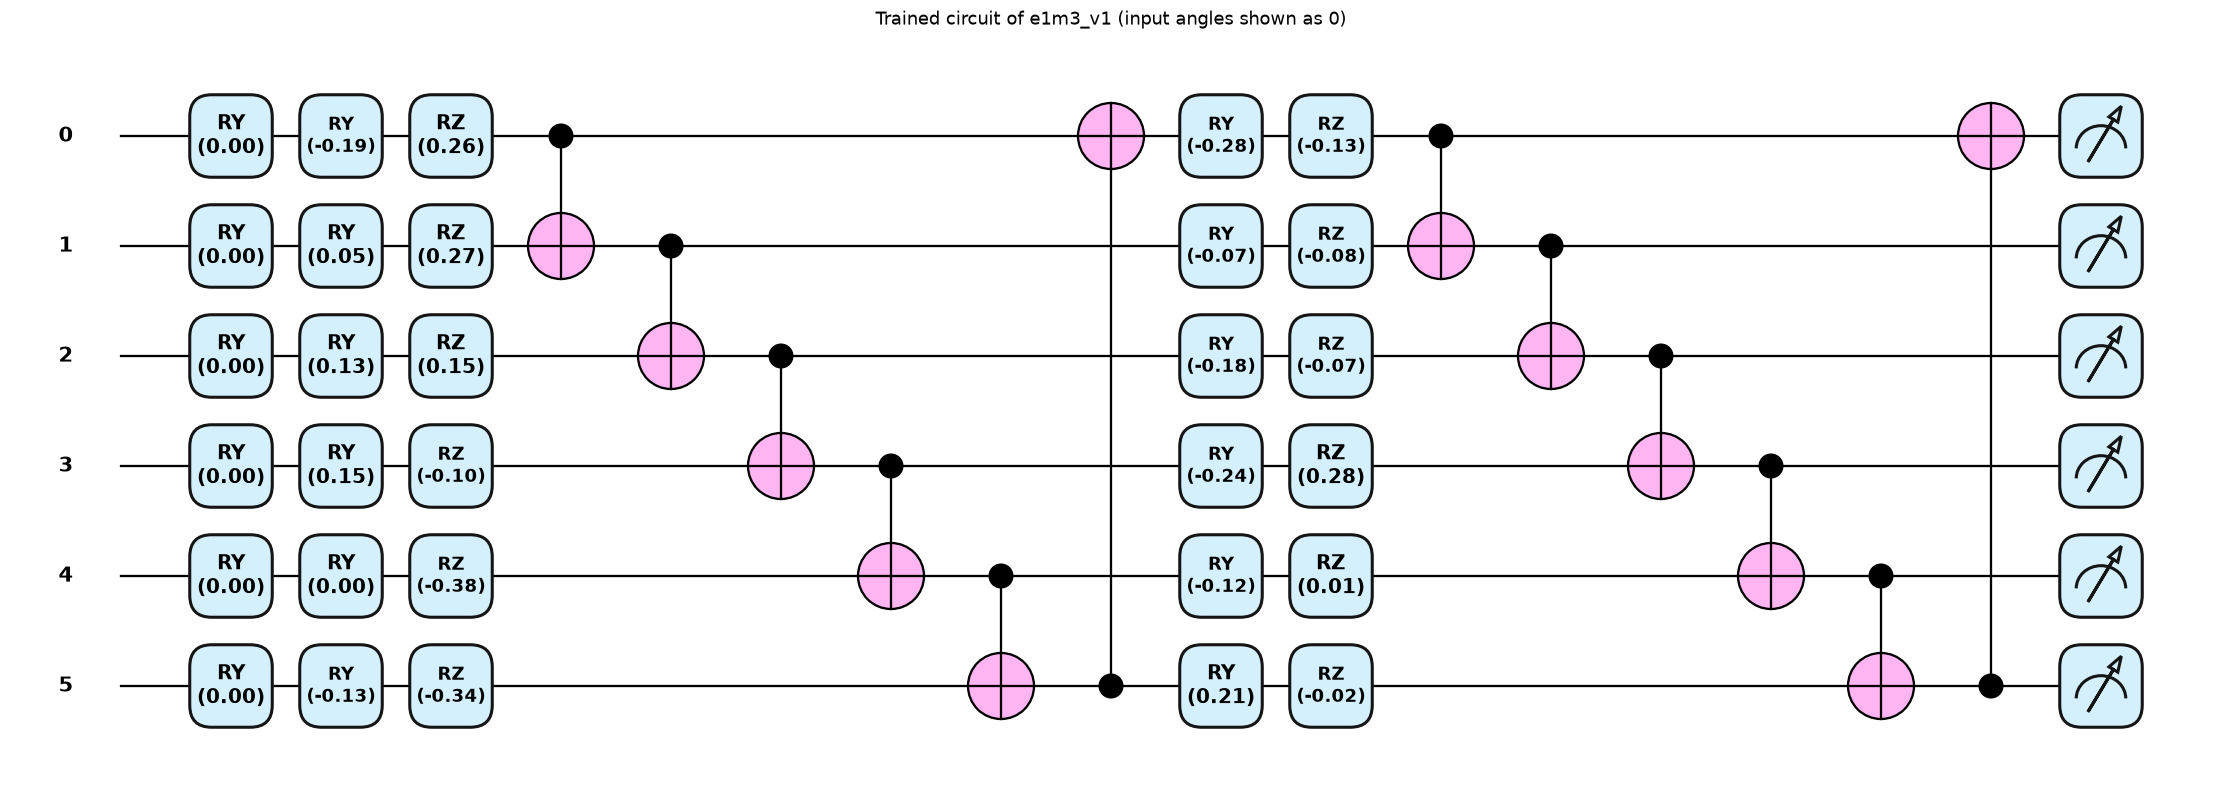

In [2]:
import torch, pennylane as qml
from corridor_qnn.full_models import load_full

model = load_full(RESULTS / 'E1M3' / RUNS['E1M3'] / 'quantum.pt', 'quantum')
total = sum(p.numel() for p in model.parameters())
circuit_params = model.core.weights.numel()
print(f'total parameters: {total:,}   circuit parameters: {circuit_params}   '
      f'qubits: {model.qubits}   layers: {model.layers}   learned quantum gain: {float(model.quantum_gain.detach()):.2f}')

dev = qml.device('default.qubit', wires=model.qubits)
@qml.qnode(dev)
def circuit(angles, weights):
    for w in range(model.qubits):
        qml.RY(angles[w], wires=w)
    for layer in range(weights.shape[0]):
        for w in range(model.qubits):
            qml.RY(weights[layer, w, 0], wires=w)
            qml.RZ(weights[layer, w, 1], wires=w)
        for w in range(model.qubits):
            qml.CNOT(wires=[w, (w + 1) % model.qubits])
    return [qml.expval(qml.PauliZ(w)) for w in range(model.qubits)]

weights = model.core.weights.detach().double()
fig, ax = qml.draw_mpl(circuit, decimals=2, style='pennylane')(np.zeros(model.qubits), weights)
fig.suptitle('Trained circuit of e1m3_v1 (input angles shown as 0)', y=1.02)
plt.show()

## 3. Building a teacher that can finish the levels

The student copies the teacher, so the teacher's completion rate is roughly a ceiling on the student's. Each new level exposed parts of Doom the planner didn't understand yet. We found them by **tracing episodes step by step** and reading the level geometry from the WAD, then fixing the planner to match the real game rules. The main capabilities, in the order the levels demanded them:

| Level | Game mechanic | What the planner learned to do | Why it matters |
|---|---|---|---|
| E1M1 | Doors | Press USE once and wait; pressing again reverses a door | Otherwise the agent fights the door forever |
| E1M1 | Combat | Skip distant or ammo-less fights; switch only to weapons with ammo | Saves health and time for the route |
| E1M2 | Keys | Treat locked doors as walls until the key has been touched | Gives a reason to fetch the key |
| E1M2 | Lifts, platforms | Use live floor and ceiling heights from the engine | Moving sectors are not static walls |
| E1M2 | Switches, walk lines | Treat them as sub-goals, scored by what they open (one-step lookahead) | The exit is often sealed until a switch is used |
| E1M2 | Ledges | One-way drops from high floors to low ones | You can jump down, but not climb up |
| E1M3 | Nukage | Cross damaging floors only when needed, keep away from pit edges, and slow down beside them | Falling in costs health and progress |
| E1M3 | Missed presses | A switch counts as used only once its sector actually starts moving | The USE ray can graze the wall next to a switch |
| E1M3 | Small lifts | Brake and stand still on the platform; run to a lift that was called from far away | Momentum carries the player off a 64-unit platform |
| E1M3 | Backward planning | Find what blocks the route to the exit or missing key, and do that first | E1M3's key sits on a pedestal lowered by a switch elsewhere |
| E1M3 | Stairs | Follow Doom's stair-building rule to know which sectors rise | Only the first step is tagged in the map data |
| E1M3 | Narrow gaps | Keep a channel across 34–64-unit openings | Inflating walls for clearance sealed a real 44-unit passage |

New behaviour sits behind an opt-in navigation version (`improved2`), so earlier trained students keep seeing exactly the waypoints they were trained on. We checked this: `e1m2_v3` still completes 19/20, and the new teacher completes 8/8 on E1M1 and 8/8 on E1M2.

The map below is E1M3 as the planner sees it, with damaging floors in green and the objectives marked.

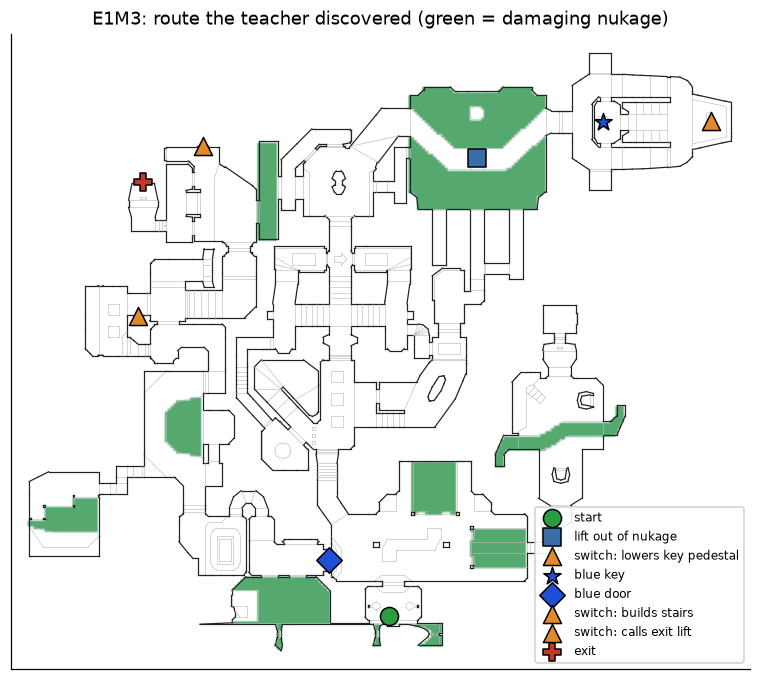

In [3]:
from corridor_qnn.full_navigation import Navigator, read_map
iwad = load('E1M3', 'eval_torch.json')['summary']['iwad']
nav = Navigator(iwad, 'E1M3', 'improved2')
verts, lines, sides, sectors = read_map(iwad, 'E1M3')
xy = np.asarray(verts, float)

fig, ax = plt.subplots(figsize=(9, 7.5))
haz = np.ma.masked_where(~nav.hazard, nav.hazard)
h, w = nav.hazard.shape
ax.imshow(haz, origin='lower', cmap='Greens', vmin=0, vmax=1.4, alpha=0.8,
          extent=[nav.origin[0] - 8, nav.origin[0] + w * nav.cell - 8, nav.origin[1] - 8, nav.origin[1] + h * nav.cell - 8])
for v1, v2, flags, special, tag, right, left in lines:
    solid = left == 65535
    ax.plot(*xy[[v1, v2]].T, color='#222' if solid else '#bbb', lw=0.8 if solid else 0.4)
marks = [((-788, -216), 'start', 'o', '#2a9d3f'),
         ((-288, 2400), 'lift out of nukage', 's', '#3b6ea8'),
         ((1052, 2612), 'switch: lowers key pedestal', '^', '#e08a2c'),
         ((432, 2608), 'blue key', '*', '#1f4fd6'),
         ((-1136, 104), 'blue door', 'D', '#1f4fd6'),
         ((-2224, 1496), 'switch: builds stairs', '^', '#e08a2c'),
         ((-1856, 2472), 'switch: calls exit lift', '^', '#e08a2c'),
         ((-2196, 2264), 'exit', 'P', '#c0392b')]
for (x, y), label, m, c in marks:
    ax.scatter(x, y, marker=m, s=140, color=c, edgecolor='k', zorder=5, label=label)
ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
ax.set_title('E1M3: route the teacher discovered (green = damaging nukage)')
ax.legend(loc='lower right', fontsize=8, framealpha=0.9)
plt.show()

Teacher completion rate on E1M3, measured on 40 seeds (800–839) at each stage of the planner work. Only the changes we kept are shown. The early stages come from 8-seed runs, scaled to a percentage.

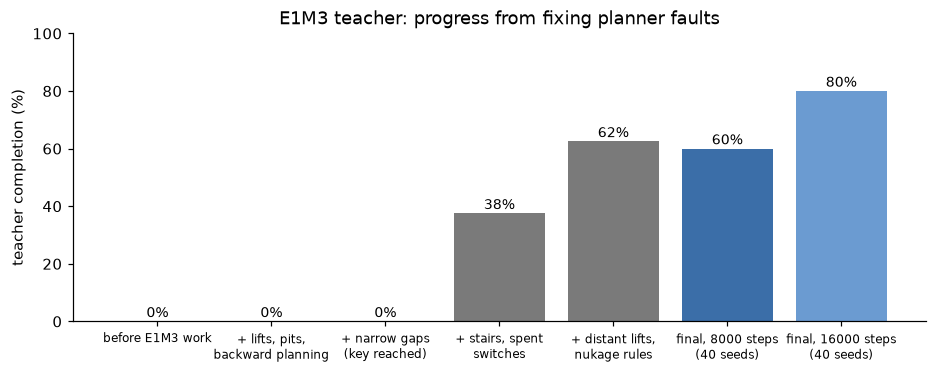

In [4]:
stages = ['before E1M3 work', '+ lifts, pits,\nbackward planning', '+ narrow gaps\n(key reached)',
          '+ stairs, spent\nswitches', '+ distant lifts,\nnukage rules', 'final, 8000 steps\n(40 seeds)', 'final, 16000 steps\n(40 seeds)']
rate = [0/8, 0/8, 0/8, 3/8, 5/8, 24/40, 32/40]
fig, ax = plt.subplots(figsize=(10, 3.4))
bars = ax.bar(stages, np.array(rate) * 100, color=[COLORS['teacher']] * 5 + ['#3b6ea8', '#6b9bd1'])
for b, r in zip(bars, rate):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1.5, f'{r:.0%}', ha='center', fontsize=9)
ax.set_ylabel('teacher completion (%)'); ax.set_ylim(0, 100)
ax.set_title('E1M3 teacher: progress from fixing planner faults')
plt.xticks(fontsize=8); plt.show()

## 4. Training the quantum student

For each level we:

1. ran the teacher on many episodes in parallel and recorded every decision: 100k decisions for E1M2 and 200k for E1M3;
2. trained the hybrid model for 12 epochs with cross-entropy against the teacher's action;
3. kept the checkpoint that played best in a few short validation games.

"Held-out accuracy" is how often the student picks the teacher's action on a whole episode it was not trained on.

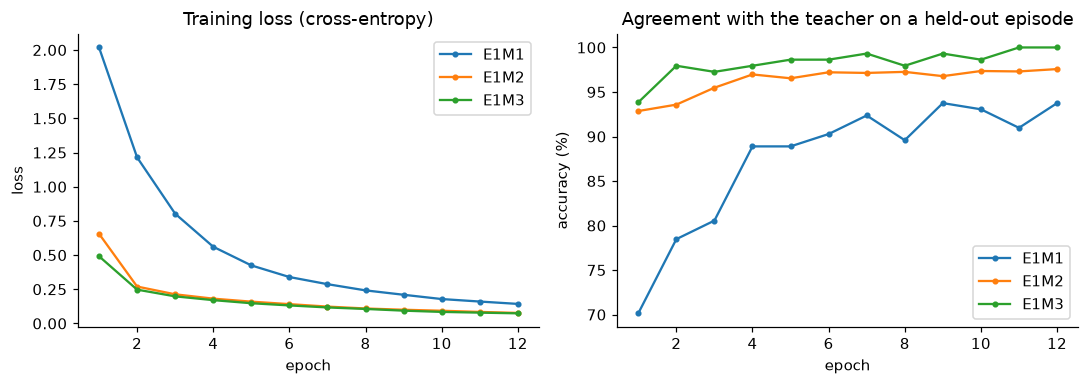

E1M1: 6,000 decisions; final loss 0.143; held-out accuracy 93.8%
E1M2: 100,000 decisions; final loss 0.077; held-out accuracy 97.6%
E1M3: 200,000 decisions; final loss 0.074; held-out accuracy 100.0%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for level in RUNS:
    hist = load(level, 'training.json')['history']
    ep = [h['epoch'] for h in hist]
    axes[0].plot(ep, [h['loss'] for h in hist], marker='o', ms=3, label=level)
    axes[1].plot(ep, [h['episode_heldout_accuracy'] * 100 for h in hist], marker='o', ms=3, label=level)
axes[0].set(title='Training loss (cross-entropy)', xlabel='epoch', ylabel='loss')
axes[1].set(title='Agreement with the teacher on a held-out episode', xlabel='epoch', ylabel='accuracy (%)')
axes[0].legend(); axes[1].legend(); plt.tight_layout(); plt.show()
for level in RUNS:
    t = load(level, 'training.json')
    print(f"{level}: {t['samples']:,} decisions; final loss {t['history'][-1]['loss']:.3f}; "
          f"held-out accuracy {t['history'][-1]['episode_heldout_accuracy']:.1%}")

Agreeing with the teacher on 94–100% of a held-out episode's decisions doesn't mean finishing 97% of levels. One wrong decision at a bad moment, such as walking off a ledge into nukage, can end an episode. So we judge models only by **playing full episodes on seeds never used in training**.

## 5. Results: does the trained agent finish the levels?

Each model is evaluated on fixed seeds (800 onwards) at its training step limit. The step limit matters because one of the student's features is elapsed time divided by the limit. Then the same weights are evaluated with the circuit executed in PennyLane's `default.qubit` simulator.

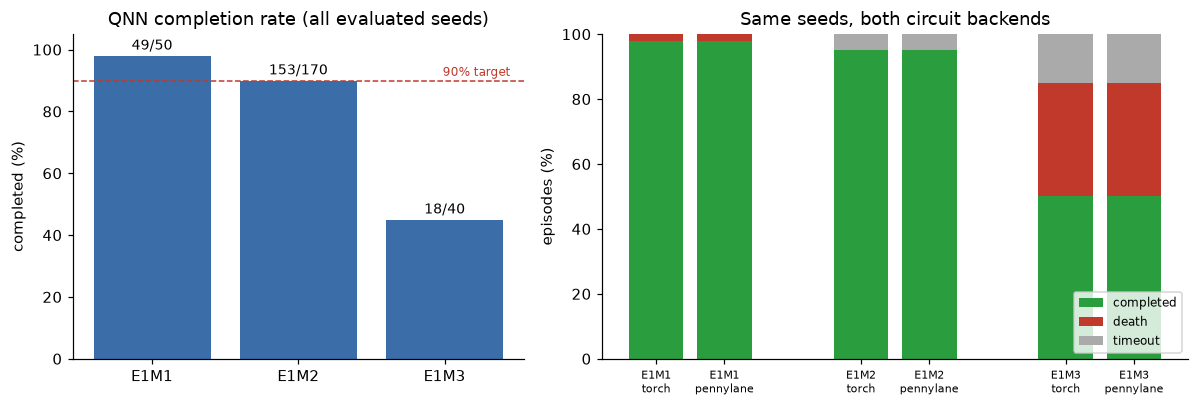

In [6]:
overall = {'E1M1': (49, 50), 'E1M2': (153, 170), 'E1M3': (18, 40)}   # all seeds evaluated, from docs/LEVEL_PROGRESS.md
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={'width_ratios': [1, 1.3]})

x = np.arange(len(overall))
rates = [c / n * 100 for c, n in overall.values()]
b = axes[0].bar(x, rates, color=COLORS['torch'])
axes[0].axhline(90, ls='--', color='#c0392b', lw=1); axes[0].text(2.45, 91.5, '90% target', color='#c0392b', fontsize=8, ha='right')
for xi, (c, n) in zip(x, overall.values()):
    axes[0].text(xi, c / n * 100 + 2, f'{c}/{n}', ha='center', fontsize=9)
axes[0].set_xticks(x, list(overall)); axes[0].set_ylim(0, 105)
axes[0].set(title='QNN completion rate (all evaluated seeds)', ylabel='completed (%)')

outcomes = ['completed', 'death', 'timeout']; oc = {'completed': '#2a9d3f', 'death': '#c0392b', 'timeout': '#aaa'}
labels, bottoms = [], []
for i, level in enumerate(RUNS):
    for j, backend in enumerate(['torch', 'pennylane']):
        eps = load(level, f'eval_{backend}.json')['episodes']
        pos = i * 3 + j; base = 0
        for o in outcomes:
            k = sum(e['outcome'] == o for e in eps)
            axes[1].bar(pos, k / len(eps) * 100, bottom=base, color=oc[o], label=o if pos == 0 else None)
            base += k / len(eps) * 100
        labels.append((pos, f'{level}\n{backend}'))
axes[1].set_xticks([p for p, _ in labels], [l for _, l in labels], fontsize=7)
axes[1].set(title='Same seeds, both circuit backends', ylabel='episodes (%)')
axes[1].legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

### Torch vs PennyLane, episode by episode

If the PennyLane circuit computes the same function as our PyTorch simulator, every episode should play out identically: same outcome and same number of steps, since the game is deterministic for a given seed. The cell below checks every evaluated episode.

In [7]:
for level in RUNS:
    t = load(level, 'eval_torch.json')['episodes']; p = load(level, 'eval_pennylane.json')['episodes']
    same = sum(a['outcome'] == b['outcome'] and a['steps'] == b['steps'] for a, b in zip(t, p))
    print(f'{level}: {same}/{len(t)} episodes identical (outcome and step count)')
print()
for level in ('E1M2', 'E1M3'):
    print(level, 'parity on recorded game states:')
    print('   ' + (RESULTS / level / RUNS[level] / 'pennylane_parity.txt').read_text().strip().replace('\n', '\n   '))

E1M1: 50/50 episodes identical (outcome and step count)
E1M2: 20/20 episodes identical (outcome and step count)
E1M3: 20/20 episodes identical (outcome and step count)

E1M2 parity on recorded game states:
   random angles (512): max |<Z> torch - pennylane| = 6.56e-07
   game states (2000): max |logit diff| = 8.11e-06, max |value diff| = 1.04e-07, argmax action agreement = 100.0000%
E1M3 parity on recorded game states:
   random angles (512): max |<Z> torch - pennylane| = 8.94e-07
   game states (2000): max |logit diff| = 6.20e-06, max |value diff| = 1.19e-07, argmax action agreement = 100.0000%


Expectation values agree to about 10⁻⁶, which is floating-point rounding, and the chosen action agrees on 100% of 2,000 real game states. The trained quantum weights therefore transfer to a standard quantum framework unchanged. PennyLane is only a simulator here too, but it's an independent one.

## 6. Does the quantum circuit actually contribute?

A hybrid model can learn to ignore its quantum part and let the classical residual path do all the work. We tested this by setting the learned `quantum_gain` to zero, which removes the circuit's contribution, and replaying the same seeds.

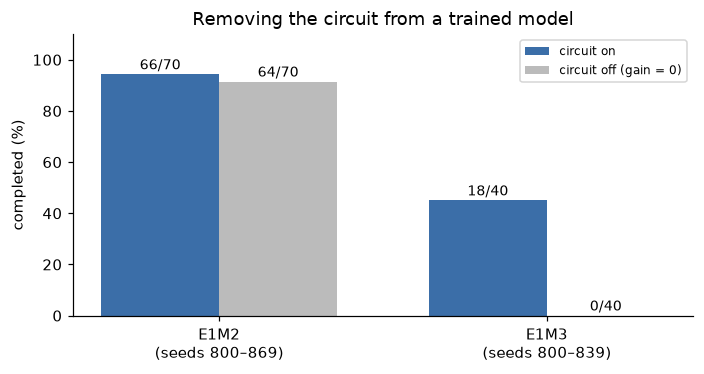

In [8]:
ablation = {'E1M2\n(seeds 800–869)': ((66, 70), (64, 70)), 'E1M3\n(seeds 800–839)': ((18, 40), (0, 40))}
fig, ax = plt.subplots(figsize=(6.5, 3.5))
w = 0.36
for i, (name, ((c1, n1), (c0, n0))) in enumerate(ablation.items()):
    ax.bar(i - w / 2, c1 / n1 * 100, w, color=COLORS['torch'], label='circuit on' if i == 0 else None)
    ax.bar(i + w / 2, c0 / n0 * 100, w, color='#bbb', label='circuit off (gain = 0)' if i == 0 else None)
    ax.text(i - w / 2, c1 / n1 * 100 + 2, f'{c1}/{n1}', ha='center', fontsize=9)
    ax.text(i + w / 2, c0 / n0 * 100 + 2, f'{c0}/{n0}', ha='center', fontsize=9)
ax.set_xticks(range(len(ablation)), list(ablation)); ax.set_ylim(0, 110)
ax.set(ylabel='completed (%)', title='Removing the circuit from a trained model')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**How to read this.**

* On **E1M2** the circuit barely matters (66 vs 64 of 70). The classical path made almost all the decisions.
* On **E1M3** the trained model **depends on its circuit**. Without it, no episode finishes. We confirmed this with two independent switches: the evaluation flag `--quantum-disabled`, and zeroing the gain in a separate script.
* **This is not a quantum advantage.** Removing a component from a trained model only shows that this model uses it. A fair test needs a classical model of the same size trained on the same E1M3 data, and we haven't run that yet. On E1M2, the same-sized classical model trained on the same data scored 62/70, against 66/70 for the hybrid. That gap is within the run-to-run noise we observed.
* We also tried richer circuits: data re-uploading, 4 layers, and ZZ correlators. None beat the simple 2-layer circuit on E1M2.

## 7. What the agent's gameplay looks like

Frames sampled from recorded episodes of the trained QNN. The full animated GIFs are in `results/levels/<level>/<run>/`.

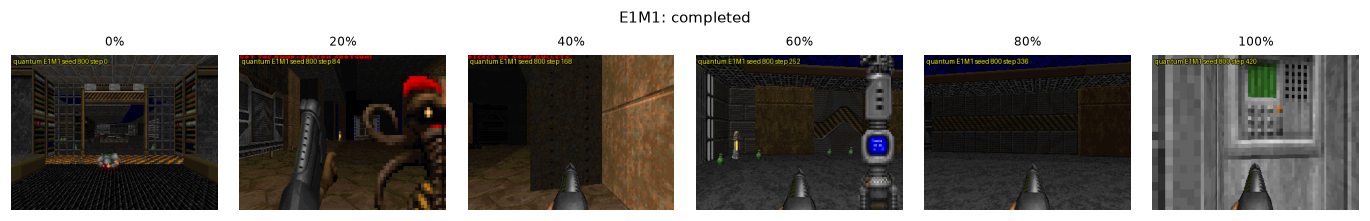

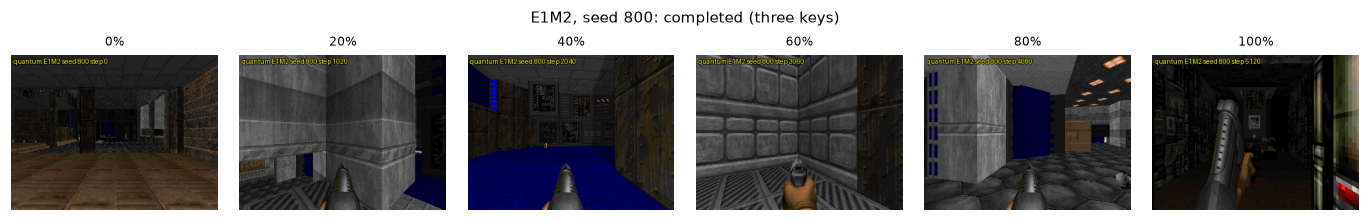

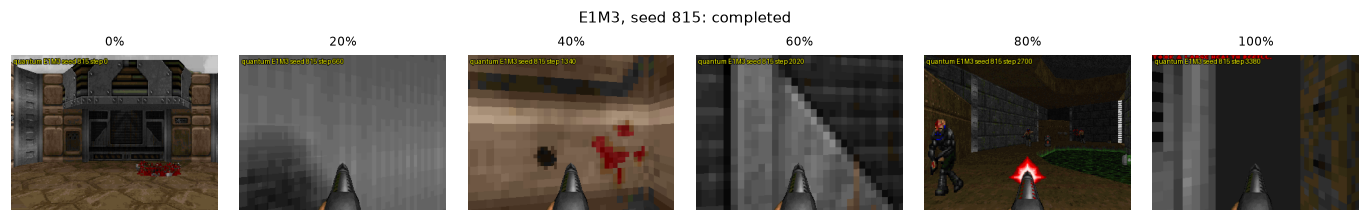

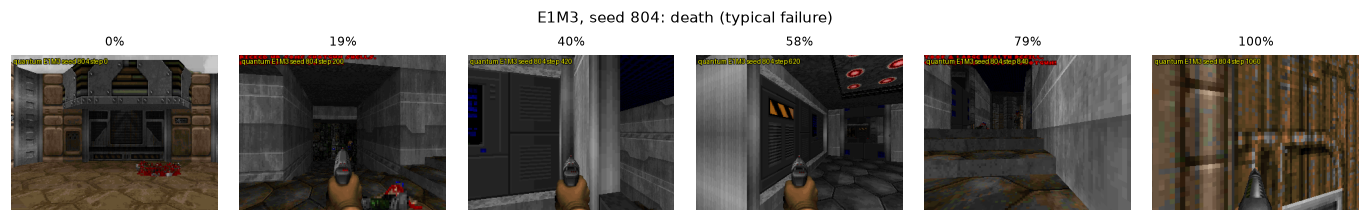

In [9]:
def strip(path, n=6, title=None):
    gif = Image.open(path); total = gif.n_frames
    fig, axes = plt.subplots(1, n, figsize=(2.1 * n, 2))
    for ax, k in zip(axes, np.linspace(0, total - 1, n).astype(int)):
        gif.seek(int(k)); ax.imshow(gif.convert('RGB')); ax.axis('off')
        ax.set_title(f'{k / (total - 1):.0%}', fontsize=8)
    fig.suptitle(title or path.name, fontsize=10); plt.tight_layout(); plt.show()

strip(RESULTS / 'E1M1/e1m1_v4/qnn_E1M1.gif', title='E1M1: completed')
strip(RESULTS / 'E1M2/e1m2_v3/qnn_E1M2_seed800.gif', title='E1M2, seed 800: completed (three keys)')
strip(RESULTS / 'E1M3/e1m3_v1/qnn_E1M3_seed815_completed.gif', title='E1M3, seed 815: completed')
strip(RESULTS / 'E1M3/e1m3_v1/qnn_E1M3_seed804_death.gif', title='E1M3, seed 804: death (typical failure)')

Animated versions (shown when the notebook is opened from the `notebooks/` folder):

| E1M1 | E1M2 | E1M3 |
|---|---|---|
| ![E1M1](../results/levels/E1M1/e1m1_v4/qnn_E1M1.gif) | ![E1M2](../results/levels/E1M2/e1m2_v3/qnn_E1M2_seed800.gif) | ![E1M3](../results/levels/E1M3/e1m3_v1/qnn_E1M3_seed815_completed.gif) |

## 8. Summary, limitations and next steps

**What we achieved**

* A 6-qubit, 24-parameter variational circuit inside a ~70k-parameter hybrid network finishes **E1M1 98%** and **E1M2 90%** of the time on unseen seeds, and **E1M3 45%**.
* Every model was verified with PennyLane: identical decisions and identical games.
* Teacher quality, not model capacity, turned out to be the main limit. Most of the improvement came from finding and modelling real Doom mechanics in the planner.

**Limitations, stated plainly**

* The agent relies on a **privileged planner** that reads the level file. It is not learning to explore from pixels alone.
* Results use skill 1 (easiest) and the circuit is **simulated**, not run on quantum hardware.
* We haven't shown a quantum advantage: on E1M2 the circuit barely mattered, and on E1M3 we haven't trained a classical comparison.
* E1M3 is below the 90% target. The teacher itself finishes 60% at the 8,000-step limit (80% with 16,000 steps), and the student loses some of that through imitation errors, mostly in the nukage room. E1M4 and later levels haven't been solved.

**Next steps**

1. Train the same-sized classical model on the E1M3 data, the fair test of whether the circuit helps.
2. Raise the E1M3 teacher further and collect more student-driven corrections in the nukage section.
3. Run the trained circuit on noisy simulators or real hardware to see how robust its decisions are.

Full experiment log, including approaches that didn't work: `docs/LEVEL_PROGRESS.md`.